In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from ml_code.data import load_dataset, preprocess_ag_dataset, audit_dataset, CLASS_MAPPING
from ml_code.classical_model import build_tfidf_logreg_pipeline, save_sklearn_model_with_metrics
from ml_code.transformer_model import train_transformer_embedding_classifier, save_transformer_model_with_metrics
from ml_code.evaluation import compare_model_predictions, get_low_confidence_examples, get_both_wrong_examples
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
import os

/home/andrej-damjanovski/ml-study/ml-interns-mk-2026/interns/andrej/week_5/notebooks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_train = load_dataset("train.csv")

In [3]:
df_test = load_dataset("test.csv")

In [4]:
df_train.head()

,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


In [5]:
print(f"Number of NaNs: {df_train.isna().sum().sum()} | Rows: {len(df_train)} | Cols: {df_train.shape[1]}")

Number of NaNs: 0 | Rows: 120000 | Cols: 3


In [6]:
train_processed = preprocess_ag_dataset(df_train)
test_processed = preprocess_ag_dataset(df_test)

In [7]:
test_processed.head()

,text,class
0,Fears for T N pension after talks\nUnions repr...,3
1,The Race is On: Second Private Team Sets Launc...,4
2,Ky. Company Wins Grant to Study Peptides (AP)\...,4
3,Prediction Unit Helps Forecast Wildfires (AP)\...,4
4,Calif. Aims to Limit Farm-Related Smog (AP)\nA...,4


In [8]:
os.makedirs("../examples", exist_ok=True)

with open("../examples/examples.txt", "w", encoding="utf-8") as f:
    for i, row in test_processed.head(20).iterrows():
        f.write(f"[{i}] {row['text']}\n\n")

Label distribution:
class
3    30000
4    30000
2    30000
1    30000
Name: count, dtype: int64


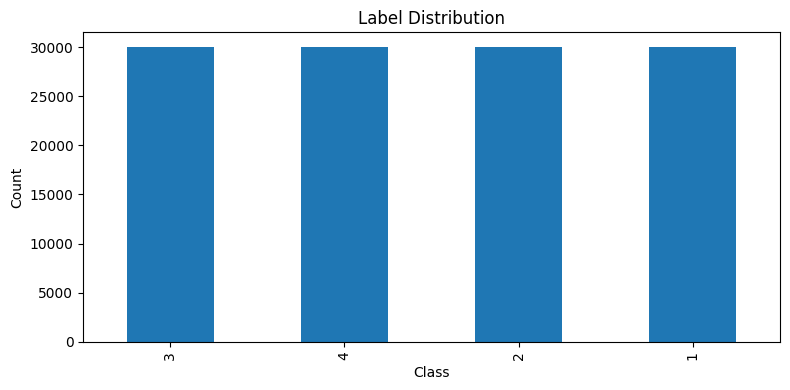


Text length summary:
count    120000.000000
mean        236.258475
std          66.457755
min          17.000000
25%         196.000000
50%         232.000000
75%         266.000000
max        1012.000000
Name: text_length_chars, dtype: float64


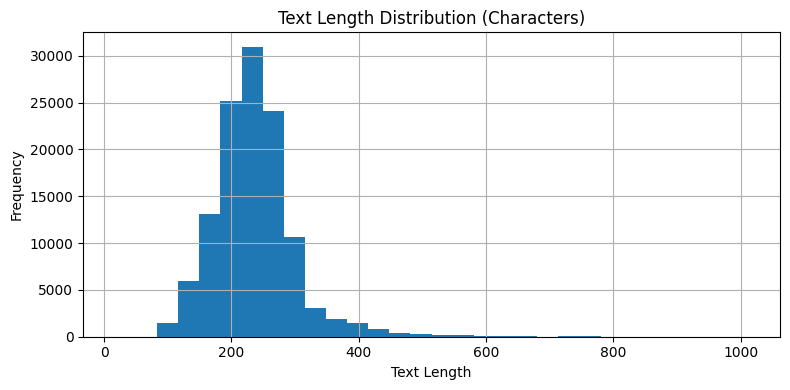


Word length summary:
count    120000.000000
mean         37.844617
std          10.088702
min           4.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: text_length_words, dtype: float64


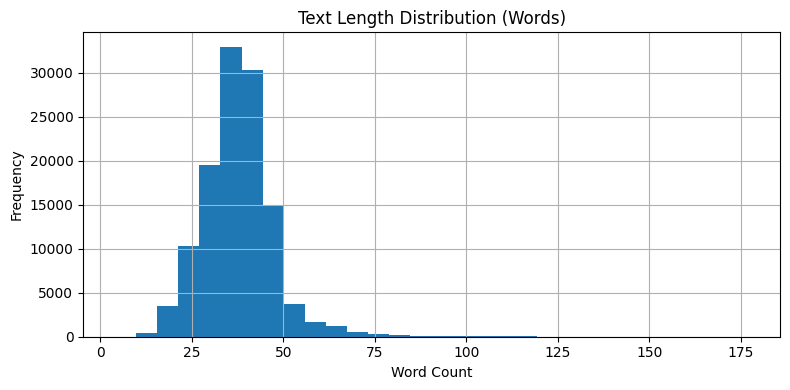


Three example rows per label:
     class  \
0        3   
1        3   
2        3   
78       4   
79       4   
80       4   
448      2   
449      2   
450      2   
492      1   
493      1   
494      1   

                                                                                                                                                                                                                                                                                                                                                                                                       text  
0                                                                                                                                                                                                                                                         Wall St. Bears Claw Back Into the Black (Reuters)\nReuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green

In [9]:
audit_dataset(train_processed)

## Data Audit and Label Design

The AG News dataset ships with an official train/test split of 120 000 and 7 600 articles respectively, each containing a title, a short description, and an integer class index. During preprocessing the title and description are concatenated into a single `text` field. There are no missing values anywhere in the dataset, and the text length is narrow and consistent — a typical article is around 38 words. The shortest articles (under 50 characters) are worth watching: a one-line headline rarely carries enough signal to classify confidently.

The dataset has four labels — World, Sports, Business, and Sci/Tech — each with exactly 30 000 training examples. Perfect balance means accuracy and macro F1 carry the same information, and no class-weighting or resampling is needed. Model comparisons are fair across all four classes.


The most likely confusion pairs are **Business and Sci/Tech** and **World and Sports**. On the Business/Sci-Tech boundary, the original labellers appear to have used a company-based heuristic: any article whose main actor is a technology company (Google, Intel, Apple) was tagged Sci/Tech, even when the story is about IPO mechanics, product delays, or competitive pricing — topics that are Business in content. This produces systematic label noise that both models inherit. The World/Sports overlap surfaces specifically around the Olympic Games: AG News treats the Olympics as a geopolitical event and labels all Olympic coverage as World, but the actual content — race results, athlete profiles, medal tallies — is indistinguishable from ordinary Sports reporting.

Some examples are clearly noisy or mislabeled. The Google IPO eligibility article and the Charles Schwab rivals piece are tagged Sci/Tech but contain no technical content; both are straightforwardly Business stories. Conversely, several Olympic articles tagged World read as pure Sports to any model and any human reader. A few legitimate Sports articles are also hard to classify because they are written in a lyrical, non-literal style (no sport-specific keywords), which fools keyword-based models even when the label is correct.

In [10]:
X_train , y_train = train_processed["text"], train_processed["class"]

In [11]:
X_test , y_test = test_processed["text"], test_processed["class"]

In [12]:
model_tfidf = build_tfidf_logreg_pipeline()

start_fit = time.perf_counter()
model_tfidf.fit(X_train, y_train)
fit_time = time.perf_counter() - start_fit

In [13]:
start_pred = time.perf_counter()
tfidf_preds = model_tfidf.predict(X_test)
inference_time = time.perf_counter() - start_pred


In [14]:
accuracy = accuracy_score(y_test, tfidf_preds)
macro_f1 = f1_score(y_test, tfidf_preds, average="macro")

In [15]:
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Fit time: {fit_time:.4f} seconds")
print(f"Inference time: {inference_time:.4f} seconds")
print(f"Average inference time per sample: {inference_time / len(X_test):.6f} seconds")

Accuracy: 0.9183
Macro F1: 0.9181
Fit time: 34.5879 seconds
Inference time: 0.3721 seconds
Average inference time per sample: 0.000049 seconds


## TF-IDF Baseline

The TF-IDF + Logistic Regression model achieves 91.83 % accuracy and 91.81 % macro F1 on the test set, with a fit time of 34 seconds. That combination of accuracy and speed makes it the right primary model for a real-time triage app.

In [16]:
save_sklearn_model_with_metrics(model_tfidf, "tfidf_model", accuracy,macro_f1,fit_time)

Saved to /home/andrej-damjanovski/ml-study/ml-interns-mk-2026/interns/andrej/week_5/models/tfidf_model


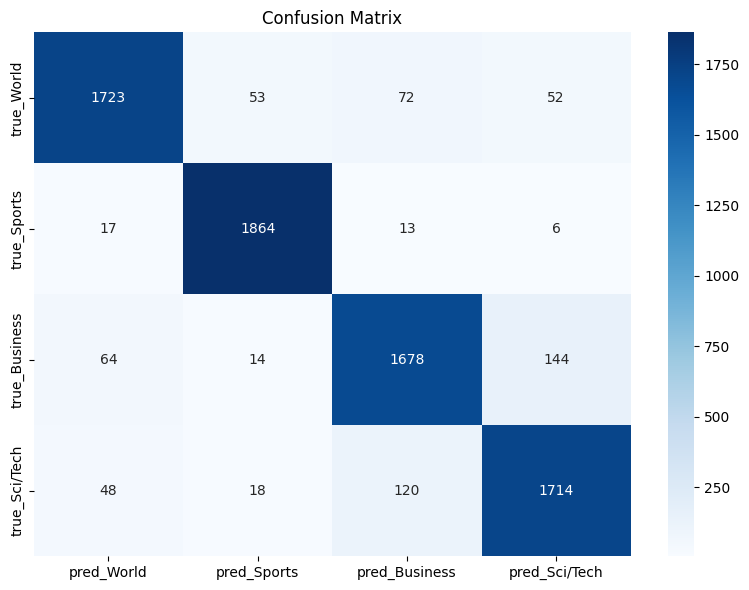

In [17]:
labels = sorted(y_test.unique())

cm = confusion_matrix(y_test, tfidf_preds, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=[f"true_{CLASS_MAPPING[l]}" for l in labels],
    columns=[f"pred_{CLASS_MAPPING[l]}" for l in labels],
)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
tfidf = model_tfidf.named_steps["tfidf"]
clf = model_tfidf.named_steps["clf"]

feature_names = tfidf.get_feature_names_out()
classes = clf.classes_

for class_id in classes:
    class_index = list(classes).index(class_id)
    coefs = clf.coef_[class_index]
    top_idx = np.argsort(coefs)[-10:][::-1]

    print(f"\nTop features for {CLASS_MAPPING[class_id]}:")
    for idx in top_idx:
        print(f"{feature_names[idx]}: {coefs[idx]:.4f}")


Top features for World:
afp: 8.2393
iraq: 6.4583
iraqi: 5.0014
nuclear: 4.8658
arafat: 4.6433
un: 4.6333
iran: 4.3483
president: 4.3350
press: 4.2328
military: 4.2323

Top features for Sports:
cup: 6.7755
coach: 6.6322
sports: 6.1117
league: 5.4712
team: 5.2883
baseball: 5.0250
olympic: 5.0190
stadium: 4.8396
players: 4.5320
season: 4.4988

Top features for Business:
economy: 4.8662
hellip: 4.7982
fullquote: 4.4729
oil: 4.4653
bank: 4.4569
tax: 4.2900
economic: 4.1740
airlines: 4.1147
forbes: 4.0906
company: 3.9426

Top features for Sci/Tech:
space: 6.5048
nasa: 6.4753
internet: 6.2327
scientists: 5.5255
software: 5.4642
apple: 4.8612
web: 4.7912
microsoft: 4.6114
technology: 4.5149
linux: 4.3513


The top features per class are mostly sensible — geopolitical terms for World, sport-specific words for Sports, company and technology names for Sci/Tech. Business is largely correct too, but two of its top features, `hellip` and `fullquote`, are HTML scraping artifacts rather than semantic signals. The model has learned a formatting shortcut that happens to correlate with Business articles in this particular dataset; it would likely break on text from a different source.

The two main confusion axes mirror what the data audit already flagged. On the Business/Sci-Tech boundary the model makes errors when articles about technology companies are framed in financial terms — IPO mechanics, product delays, competitive pricing — content that sits closer to Business but carries a tech company as its subject. On the Sports/World boundary, Olympic coverage is labelled World by the dataset but reads as pure Sports, so the model confidently predicts Sports and is not obviously wrong.

In [19]:
encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
classifier = LogisticRegression(max_iter=400)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 1894.07it/s]


In [20]:
train_res = train_transformer_embedding_classifier(encoder,classifier,X_train.tolist(),y_train)

Batches: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 1875/1875 [58:56<00:00,  1.89s/it]


In [21]:
start_embed = time.perf_counter()
X_emb = encoder.encode(
        X_test.tolist(),
        show_progress_bar=True,
        convert_to_numpy=True,
    )
embedding_transf_time = time.perf_counter() - start_embed

Batches: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 238/238 [03:32<00:00,  1.12it/s]


In [22]:
start_pred = time.perf_counter()
transformers_preds = classifier.predict(X_emb)
prediction_time = time.perf_counter() - start_pred

total_inference_transf_time = embedding_transf_time + prediction_time

In [23]:
accuracy = accuracy_score(y_test, transformers_preds)
macro_f1 = f1_score(y_test, transformers_preds, average="macro")

In [24]:
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Fit time: {train_res["total_train_time_sec"]:.4f} seconds")
print(f"Inference time: {total_inference_transf_time:.4f} seconds")
print(f"Average inference time per sample: {total_inference_transf_time / len(X_test):.6f} seconds")

Accuracy: 0.8946
Macro F1: 0.8945
Fit time: 3591.6545 seconds
Inference time: 212.5453 seconds
Average inference time per sample: 0.027966 seconds


## Transformer Comparison

The transformer approach uses `sentence-transformers/all-MiniLM-L6-v2` to encode each article into a 384-dimensional semantic embedding, with a Logistic Regression classifier trained on top. This was chosen over a zero-shot classifier because it can be adapted to the specific label set and produces calibrated probabilities needed for the confidence-based review flag.

On the same test set the transformer reaches 89.46 % accuracy and 89.45 % macro F1 — about 2.4 points behind TF-IDF. It also trains roughly 100× slower and runs inference 570× slower. For a real-time triage app on structured newswire text, where topic keywords are highly predictive, TF-IDF is the clearly better primary model.

In [25]:
save_transformer_model_with_metrics(encoder,classifier, "transformers_model",accuracy, macro_f1,train_res["total_train_time_sec"])

Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  4.28it/s]

Saved to /home/andrej-damjanovski/ml-study/ml-interns-mk-2026/interns/andrej/week_5/models/transformers_model


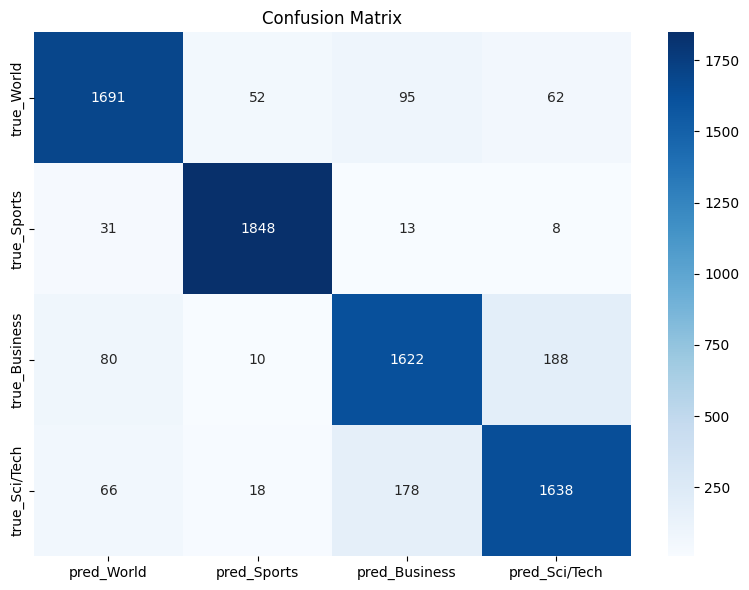

In [26]:
cm = confusion_matrix(y_test, transformers_preds, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=[f"true_{CLASS_MAPPING[l]}" for l in labels],
    columns=[f"pred_{CLASS_MAPPING[l]}" for l in labels],
)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

The transformer's theoretical advantage — understanding meaning rather than counting tokens — does not materialise on this dataset. Both models fail on the same two structural issues: the Business/Sci-Tech boundary (where dataset labels follow actor identity rather than article content) and the Olympics-as-World taxonomy (where the content is unambiguously sports but the label is World). The transformer doesn't resolve either problem; it just makes different errors on the same ambiguous examples.

In [27]:
tfidf_probs = model_tfidf.predict_proba(X_test)
tfidf_conf = tfidf_probs.max(axis=1)

tfidf_low_conf = get_low_confidence_examples(
    X=X_test,
    y_true=y_test,
    preds=tfidf_preds,
    confidences=tfidf_conf,
    label_names=CLASS_MAPPING,
    n=5,
)


Example 1
--------------------------------------------------------------------------------
True label : Sports
Prediction : Business
Confidence : 0.2863
Correct    : False
Text       : Ace's wicked run leaves us wanting more
Seven years of Pedro. Went by quickly, huh? Seven years, the best of which may very well have been the best pitching ever done in a Boston uniform. Seven years of feistiness. Seven years of blazing fastballs. Seven years of spellbinding changeups. Seven years of pitching inside, sometimes waaaaay inside. Seven years of double-digit strikeouts. Seven years of sheer virtuosity. ...

Example 2
--------------------------------------------------------------------------------
True label : World
Prediction : World
Confidence : 0.2874
Correct    : True
Text       : Mich. Elephant Gets Therapy for Arthritis
ROYAL OAK, Mich. - Like any patient, Wanda needs positive reinforcement to wrestle through her physical therapy...

Example 3
------------------------------------------

In [28]:
with open("../examples/tfidf_low_conf_examples.txt", "w", encoding="utf-8") as f:
    for i, row in tfidf_low_conf.iterrows():
        f.write(f"[{i}] {row['text']}\n\n")

Beyond those structural issues, TF-IDF struggles specifically when articles lack explicit topic keywords. A lyrical retrospective on pitcher Pedro Martinez contains no words like *baseball* or *pitcher*, so the model classifies it as Business. Similarly, a cricket article gets misclassified because the training data is US-centric and cricket never became a high-weight Sports feature. Both cases produce very low confidence scores, which is exactly when the human-review flag should trigger.

In [29]:
transformer_probs = classifier.predict_proba(X_emb)
transformer_conf = transformer_probs.max(axis=1)

transformer_low_conf = get_low_confidence_examples(
    X=X_test,
    y_true=y_test,
    preds=transformers_preds,
    confidences=transformer_conf,
    label_names=CLASS_MAPPING,
    n=5,
)


Example 1
--------------------------------------------------------------------------------
True label : Sci/Tech
Prediction : World
Confidence : 0.2987
Correct    : False
Text       : Court ruling has fat cats purring
THE future of horseracing in Britain was thrown into confusion this week as a result of a judgment by the European Court of Justice.

Example 2
--------------------------------------------------------------------------------
True label : Business
Prediction : Sci/Tech
Confidence : 0.3002
Correct    : False
Text       : Med school move delayed to 2007
The MSU College of Human Medicine won #39;t be relocated to Grand Rapids until at least 2007, and could cost only half as much as university officials originally estimated.

Example 3
--------------------------------------------------------------------------------
True label : Business
Prediction : Sports
Confidence : 0.3035
Correct    : False
Text       : Virgin dips its toe into the Pacific
SIR Richard Branson did not disa

In [30]:
with open("../examples/transformer_low_conf_examples.txt", "w", encoding="utf-8") as f:
    for i, row in transformer_low_conf.iterrows():
        f.write(f"[{i}] {row['text']}\n\n")

In [31]:
both_wrong = get_both_wrong_examples(
    X=X_test,
    y_true=y_test,
    preds_a=tfidf_preds,
    preds_b=transformers_preds,
    label_names=CLASS_MAPPING,
    model_a_name="TF-IDF",
    model_b_name="Transformer",
    n=5,
)


Example 1
--------------------------------------------------------------------------------
True label        : Sci/Tech
TF-IDF            : Business
Transformer       : Business
Text              : Some People Not Eligible to Get in on Google IPO
Google has billed its IPO as a way for everyday people to get in on the process, denying Wall Street the usual stranglehold it's had on IPOs. Public bidding, a minimum of just five shares, an open process with 28 underwriters - all this pointed to a new level of public participation. But this isn't the case.

Example 2
--------------------------------------------------------------------------------
True label        : Sci/Tech
TF-IDF            : Business
Transformer       : Business
Text              : Rivals Try to Turn Tables on Charles Schwab
By MICHAEL LIEDTKE     SAN FRANCISCO (AP) -- With its low prices and iconoclastic attitude, discount stock broker Charles Schwab Corp. (SCH) represented an annoying stone in Wall Street's wing-tipped

In [32]:
with open("../examples/both_wrong_examples.txt", "w", encoding="utf-8") as f:
    for i, row in both_wrong.iterrows():
        f.write(f"[{i}] {row['text']}\n\n")

Where the transformer is actually weaker is on idiomatic or metaphorical headlines. "Virgin dips its toe into the Pacific" is an airline expansion story, but the phrase sounds physical to a semantic embedding and gets pulled toward Sports. "Running may have defined the body" is an evolutionary biology study, but "running" and "body" sit close to Sports in the embedding space. TF-IDF would handle both correctly because the article body contains explicit anchor words like "airline" and "scientists." The transformer's strength — broad semantic generalisation — becomes a liability when the headline is figurative and the disambiguating keywords are buried in the description.


## Human Review Rule

An article is flagged for human review if any of the following conditions hold: either model's confidence falls below 0.40, the two models predict different labels, or the text is fewer than 50 characters. The confidence threshold catches cases where the probability mass is spread roughly evenly across classes; the disagreement trigger catches cases where both models are individually confident but in opposite directions — a strong signal that the article sits on a label boundary.

Looking across the 15 examples — five wrong predictions, five low-confidence cases, and five where both models fail — two patterns dominate.

The first is **non-literal writing**. Both TF-IDF and the transformer break down when the headline or body uses figurative language rather than topic keywords. The Pedro Martinez tribute contains no words like *baseball* or *pitcher*, so TF-IDF classifies it as Business. The cricket article uses "swings" and "Calypso" instead of sport-specific terms, with the same result. The transformer fails on "Virgin dips its toe into the Pacific" (predicted Sports instead of Business) and "Running may have defined the body" (predicted Sports instead of Sci/Tech) for the same reason — the embedding space is pulled by the literal meaning of the words rather than the topic of the article. In all these cases confidence is low, which is exactly what the review rule is designed to catch.

The second pattern is **label ambiguity in the dataset itself**. Several of the both-wrong examples are not really model failures — they are cases where the ground-truth label is debatable or likely wrong. The Google IPO article and the Charles Schwab piece are tagged Sci/Tech but contain no technical content; both models predict Business and are arguably more correct than the label. Olympic articles tagged World are predicted Sports by both models because the content is unambiguously sports coverage; the World label is an editorial convention, not a content description. When both models agree on a prediction that contradicts the label, that is often a signal to distrust the label rather than the model.

The low-confidence-but-correct examples follow a different logic. Articles about elephant therapy, a museum reopening, or Canada's submarine fleet are all correctly classified as World, but the confidence is very low because these topics sit far from the prototypical World story (geopolitics, conflict, elections). The model gets lucky by elimination. A human reviewer should treat these predictions as fragile: small wording changes could easily flip the output, and the label assignment is itself a judgement call.

The practical takeaway is that the review flag should be trusted. Every one of these 15 examples would benefit from a human check, either because the text is genuinely hard to classify or because the dataset label is itself questionable.